In [1]:
# %% [markdown]
# # Task 1: Price Pattern Analysis
# ## Asset: E-mini S&P 500 (ES) - 15-minute candles
# ## Data source: Supabase (full history 2020-2026)

# %%
import sys
sys.path.append('../../../../utils')
from data_loader import load_es_15min
from metrics import sharpe_ratio, max_drawdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

print("✅ Libraries and utils loaded")

✅ Libraries and utils loaded


In [ ]:
# %% [markdown]
# ### Data download with progress indicator

# %%
import pandas as pd
from tqdm import tqdm
from supabase import create_client
import os
from dotenv import load_dotenv

load_dotenv()

def load_es_15min_with_progress(start_date=None, end_date=None, session_only=False):
    supabase = create_client(
        os.getenv("SUPABASE_URL"),
        os.getenv("SUPABASE_SERVICE_ROLE_KEY") 
    )
    
    # Count total rows
    count_res = supabase.table('es_15min').select('*', count='exact').limit(0).execute()
    total = count_res.count
    print(f"📊 Total rows available: {total}")
    
    all_data = []
    offset = 0
    batch = 1000
    with tqdm(total=total, desc="Downloading data", unit="rows") as pbar:
        while True:
            query = supabase.table('es_15min').select('*').order('timestamp').range(offset, offset + batch - 1)
            if start_date:
                query = query.gte('timestamp', start_date)
            if end_date:
                query = query.lte('timestamp', end_date)
            response = query.execute()
            if not response.data:
                break
            all_data.extend(response.data)
            pbar.update(len(response.data))
            offset += batch
            if len(response.data) < batch:
                break
    
    df = pd.DataFrame(all_data)
    df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)
    df = df.sort_values('timestamp').reset_index(drop=True)
    
    if session_only:
        df = df[(df['timestamp'].dt.hour >= 9) & (df['timestamp'].dt.hour < 16)]
        df = df[~((df['timestamp'].dt.hour == 9) & (df['timestamp'].dt.minute < 30))]
        df = df[~((df['timestamp'].dt.hour == 16) & (df['timestamp'].dt.minute > 0))]
    
    return df

# Load all data
print("Loading ES 15min data from Supabase...")
df = load_es_15min_with_progress(session_only=False)
print(f"✅ Loaded {len(df):,} 15-minute candles")
print(f"Period: {df['timestamp'].min()} → {df['timestamp'].max()}")

Loading ES 15min data from Supabase...
📊 Total rows available: 144201


✅ Loaded 144,201 15-minute candles
Period: 2020-02-02 18:00:00 → 2026-05-07 00:45:00


In [6]:
# %% [markdown]
# ## 1. Resample to daily closes

# %%
# Resample to daily closes (last price of each day)
daily = df.resample('D', on='timestamp').agg({'close': 'last'}).dropna()
daily['returns'] = daily['close'].pct_change()
daily = daily.dropna()
print(f"Daily observations: {len(daily)}")
print(f"First date: {daily.index.min()}, Last date: {daily.index.max()}")

Daily observations: 1896
First date: 2020-02-03 00:00:00, Last date: 2026-05-07 00:00:00


In [7]:
# %% [markdown]
# ## 2. Daily return statistics

# %%
mean_ret = daily['returns'].mean()
median_ret = daily['returns'].median()
std_ret = daily['returns'].std()
skew = daily['returns'].skew()
kurt = daily['returns'].kurtosis()

print("="*50)
print("DAILY RETURN STATISTICS")
print("="*50)
print(f"Mean (average):      {mean_ret:.6%}")
print(f"Median:              {median_ret:.6%}")
print(f"Standard deviation:  {std_ret:.6%}")
print(f"Skewness:            {skew:.4f}")
print(f"Kurtosis (excess):   {kurt:.4f}")
print(f"Min return:          {daily['returns'].min():.6%}")
print(f"Max return:          {daily['returns'].max():.6%}")

DAILY RETURN STATISTICS
Mean (average):      0.049796%
Median:              0.072593%
Standard deviation:  1.133117%
Skewness:            0.1103
Kurtosis (excess):   9.7827
Min return:          -6.917616%
Max return:          10.715373%


In [8]:
# %% [markdown]
# ## 3. Best and worst 5 days

# %%
top5 = daily.nlargest(5, 'returns')[['close', 'returns']].copy()
bottom5 = daily.nsmallest(5, 'returns')[['close', 'returns']].copy()

print("TOP 5 GAINING DAYS")
print(top5.to_string())
print("\nWORST 5 LOSING DAYS")
print(bottom5.to_string())

TOP 5 GAINING DAYS
              close   returns
timestamp                    
2025-04-09  5455.50  0.107154
2020-03-13  2652.75  0.082866
2022-11-10  3969.25  0.054460
2020-03-24  2405.50  0.054350
2020-03-26  2577.50  0.050112

WORST 5 LOSING DAYS
              close   returns
timestamp                    
2020-03-08  2819.00 -0.069176
2020-03-11  2617.75 -0.068831
2020-03-12  2449.75 -0.064177
2025-04-04  5096.75 -0.056332
2020-03-18  2285.25 -0.049397


In [10]:
# %% [markdown]
# ## 4. Day-of-week patterns

# %%
daily['weekday'] = daily.index.dayofweek  # 0=Monday, 4=Friday, 5=Saturday, 6=Sunday
daily['weekday_name'] = daily.index.strftime('%A')
weekday_ret = daily.groupby('weekday')['returns'].mean()

# Mapeo de números a nombres (para todos los días posibles)
weekday_names = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 
                 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
weekday_ret.index = [weekday_names[i] for i in weekday_ret.index]

print("="*50)
print("AVERAGE RETURN BY WEEKDAY")
print("="*50)
print(weekday_ret.to_string())

best_wd = weekday_ret.idxmax()
worst_wd = weekday_ret.idxmin()
print(f"\nBest weekday: {best_wd} ({weekday_ret[best_wd]:.4%})")
print(f"Worst weekday: {worst_wd} ({weekday_ret[worst_wd]:.4%})")

AVERAGE RETURN BY WEEKDAY
Monday       0.002219
Tuesday      0.000523
Wednesday    0.000293
Thursday    -0.000481
Friday       0.000409
Sunday       0.000011

Best weekday: Monday (0.2219%)
Worst weekday: Thursday (-0.0481%)


In [12]:
# %% [markdown]
# ## 5. Month-of-year patterns

# %%
daily['month'] = daily.index.month
month_ret = daily.groupby('month')['returns'].mean()
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_ret.index = month_names

print("\n" + "="*50)
print("AVERAGE RETURN BY MONTH")
print("="*50)
print(month_ret.to_string())

best_month = month_ret.idxmax()
worst_month = month_ret.idxmin()
print(f"\nBest month: {best_month} ({month_ret[best_month]:.4%})")
print(f"Worst month: {worst_month} ({month_ret[worst_month]:.4%})")


AVERAGE RETURN BY MONTH
Jan    0.000252
Feb   -0.000513
Mar   -0.000445
Apr    0.000980
May    0.001105
Jun    0.000757
Jul    0.001539
Aug    0.000412
Sep   -0.001088
Oct    0.000749
Nov    0.001879
Dec    0.000356

Best month: Nov (0.1879%)
Worst month: Sep (-0.1088%)


In [14]:
# %% [markdown]
# ## 6. Consecutive day streaks

# %%
def max_streak(series):
    """Returns the maximum consecutive length of True/1 values."""
    return series.groupby((series != series.shift()).cumsum()).sum().max()

daily['up'] = (daily['returns'] > 0).astype(int)
daily['down'] = (daily['returns'] < 0).astype(int)

max_up_streak = max_streak(daily['up'])
max_down_streak = max_streak(daily['down'])

print("="*50)
print("CONSECUTIVE DAY STREAKS")
print("="*50)
print(f"Longest winning streak: {max_up_streak} days")
print(f"Longest losing streak:  {max_down_streak} days")

# --- Find periods of the longest streaks (without using .groups) ---
# For up streaks
up_streaks = daily['up'].groupby((daily['up'] != daily['up'].shift()).cumsum()).sum()
longest_up_group = up_streaks.idxmax()  # group label of the longest streak
# Mask where the streak group equals the longest group
up_streak_mask = (daily['up'] != daily['up'].shift()).cumsum() == longest_up_group
up_streak_dates = daily.index[up_streak_mask]
if len(up_streak_dates) > 0:
    up_start = up_streak_dates[0]
    up_end = up_streak_dates[-1]
    print(f"  Longest win streak period: {up_start.date()} → {up_end.date()}")
else:
    print("  Longest win streak period: could not determine")

# For down streaks
down_streaks = daily['down'].groupby((daily['down'] != daily['down'].shift()).cumsum()).sum()
longest_down_group = down_streaks.idxmax()
down_streak_mask = (daily['down'] != daily['down'].shift()).cumsum() == longest_down_group
down_streak_dates = daily.index[down_streak_mask]
if len(down_streak_dates) > 0:
    down_start = down_streak_dates[0]
    down_end = down_streak_dates[-1]
    print(f"  Longest loss streak period: {down_start.date()} → {down_end.date()}")
else:
    print("  Longest loss streak period: could not determine")

CONSECUTIVE DAY STREAKS
Longest winning streak: 10 days
Longest losing streak:  8 days
  Longest win streak period: 2024-08-08 → 2024-08-19
  Longest loss streak period: 2023-08-31 → 2023-09-22


In [15]:
# %% [markdown]
# ## 7. Correction size after large moves

# %%
threshold = 1.5 * std_ret
large_up = daily[daily['returns'] > threshold]
large_down = daily[daily['returns'] < -threshold]
print(f"Number of large up days (> +{threshold:.4%}): {len(large_up)}")
print(f"Number of large down days (< -{threshold:.4%}): {len(large_down)}")

def correction_after(df, signal_dates, direction='up', lookahead=5):
    corrections = []
    for date in signal_dates:
        idx = df.index.get_loc(date)
        if idx + lookahead < len(df):
            segment = df.iloc[idx+1:idx+1+lookahead]
            if direction == 'up':
                peak = df.iloc[idx]['close']
                min_price = segment['close'].min()
                corr = (min_price - peak) / peak
            else:
                valley = df.iloc[idx]['close']
                max_price = segment['close'].max()
                corr = (max_price - valley) / valley
            corrections.append(corr)
    return pd.Series(corrections)

lookahead = 5
up_corr = correction_after(daily, large_up.index, direction='up', lookahead=lookahead)
down_corr = correction_after(daily, large_down.index, direction='down', lookahead=lookahead)

print(f"\nAverage correction over {lookahead} days after a large up day: {up_corr.mean():.2%}")
print(f"Median correction after large up: {up_corr.median():.2%}")
print(f"Average correction after large down day: {down_corr.mean():.2%}")
print(f"Median correction after large down: {down_corr.median():.2%}")

Number of large up days (> +1.6997%): 81
Number of large down days (< -1.6997%): 100

Average correction over 5 days after a large up day: -1.50%
Median correction after large up: -0.70%
Average correction after large down day: 2.19%
Median correction after large down: 1.83%


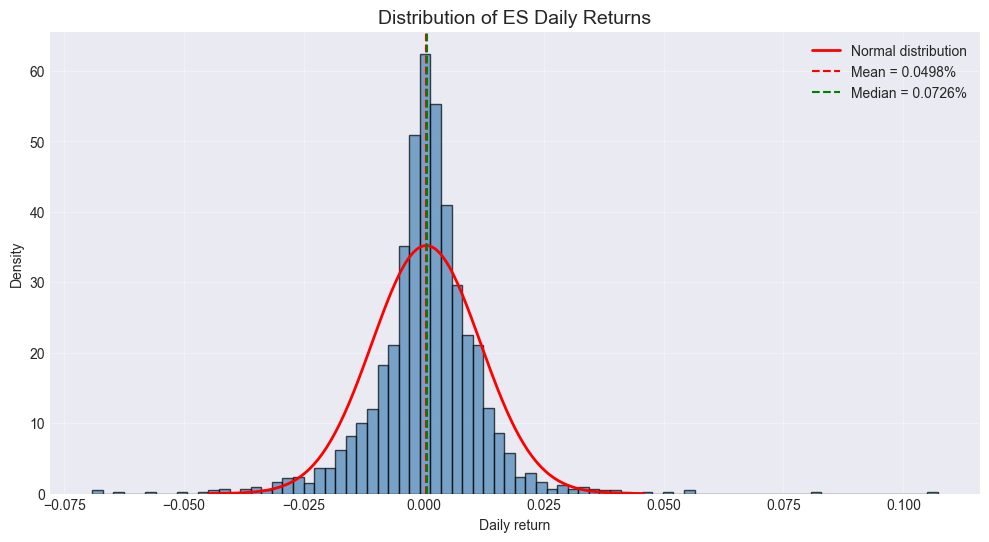

In [16]:
# %% [markdown]
# ## 8. Visualizations

# %%
# Histogram of daily returns with normal distribution overlay
fig, ax = plt.subplots(figsize=(12, 6))
n, bins, patches = ax.hist(daily['returns'], bins=80, density=True, alpha=0.7, color='steelblue', edgecolor='black')
# Overlay normal distribution
mu, sigma = mean_ret, std_ret
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
ax.plot(x, (1/(sigma * np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2), 'r-', linewidth=2, label='Normal distribution')
ax.axvline(mean_ret, color='red', linestyle='--', label=f'Mean = {mean_ret:.4%}')
ax.axvline(median_ret, color='green', linestyle='--', label=f'Median = {median_ret:.4%}')
ax.set_title('Distribution of ES Daily Returns', fontsize=14)
ax.set_xlabel('Daily return')
ax.set_ylabel('Density')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

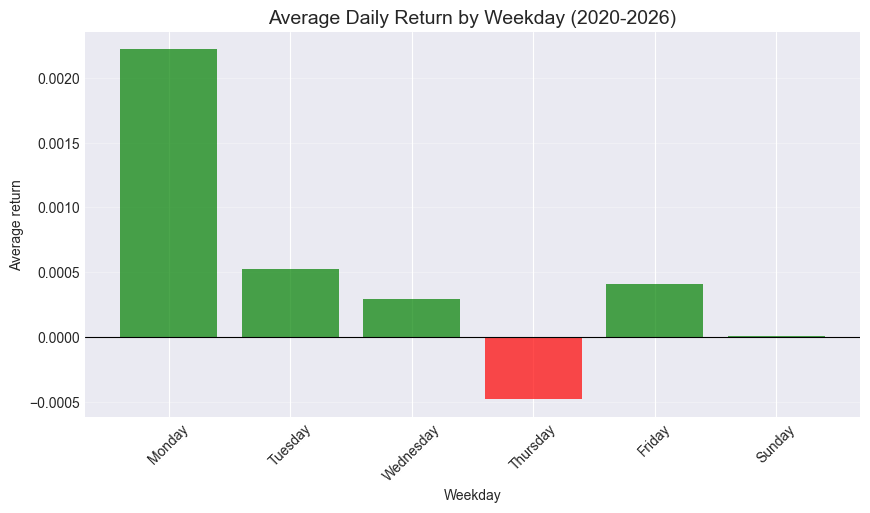

In [11]:
# %%
# Bar plot: returns by weekday (orden natural: de lunes a domingo)
# Primero aseguramos que el índice tenga el orden correcto
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Reindex para que aparezcan solo los días que existen en weekday_ret
plot_data = weekday_ret.reindex([d for d in ordered_days if d in weekday_ret.index])

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['red' if x < 0 else 'green' for x in plot_data.values]
ax.bar(plot_data.index, plot_data.values, color=colors, alpha=0.7)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average Daily Return by Weekday (2020-2026)', fontsize=14)
ax.set_ylabel('Average return')
ax.set_xlabel('Weekday')
plt.xticks(rotation=45)
ax.grid(axis='y', alpha=0.3)
plt.show()

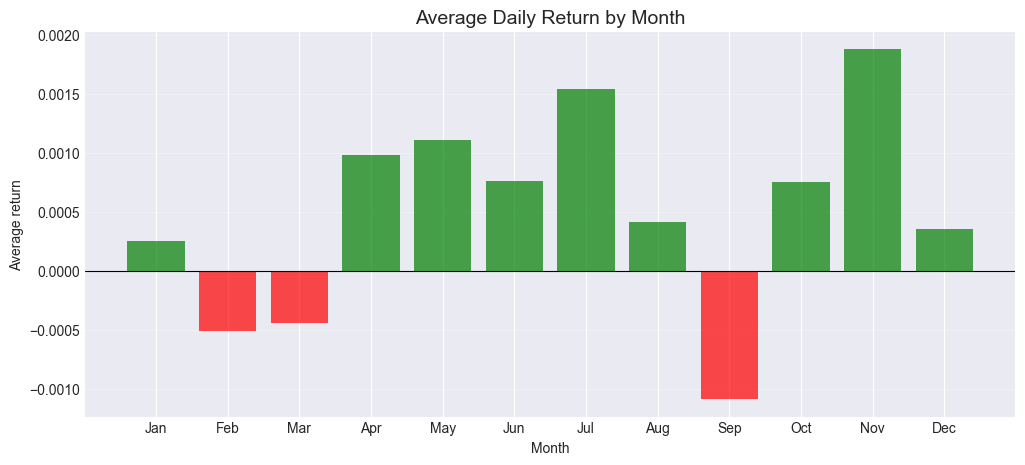

In [17]:
# %%
# Bar plot: returns by month
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['red' if x < 0 else 'green' for x in month_ret.values]
ax.bar(month_ret.index, month_ret.values, color=colors, alpha=0.7)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average Daily Return by Month', fontsize=14)
ax.set_ylabel('Average return')
ax.set_xlabel('Month')
ax.grid(axis='y', alpha=0.3)
plt.show()

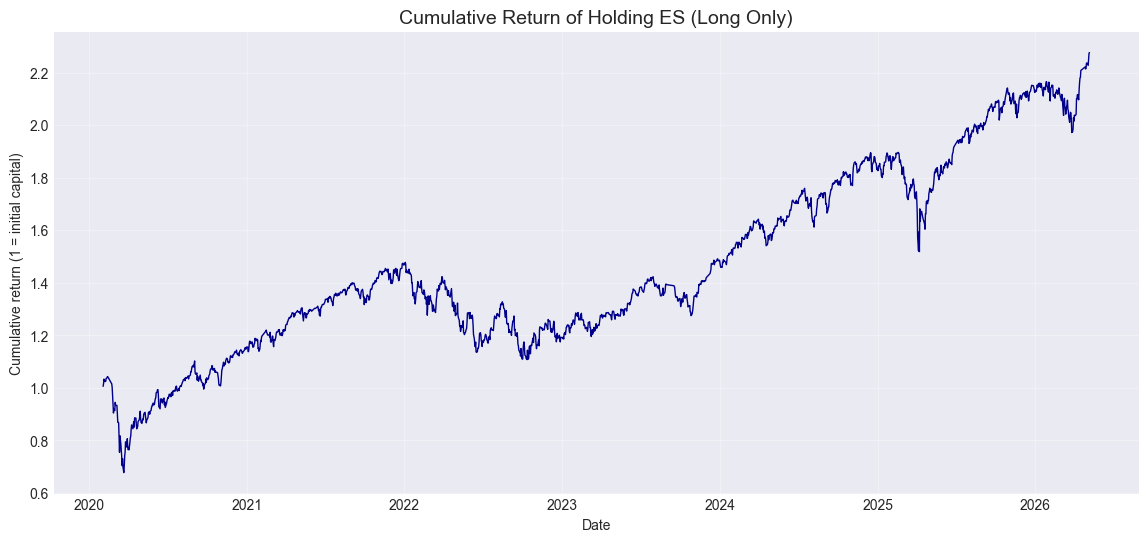

In [18]:
# %%
# Cumulative return of holding ES (long only)
daily['cum_return'] = (1 + daily['returns']).cumprod()
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily.index, daily['cum_return'], color='darkblue', linewidth=1)
ax.set_title('Cumulative Return of Holding ES (Long Only)', fontsize=14)
ax.set_ylabel('Cumulative return (1 = initial capital)')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.3)
plt.show()

In [19]:
# %% [markdown]
# ## Summary of Findings

# %%
print("\n" + "="*60)
print("SUMMARY OF TASK 1: PRICE PATTERN ANALYSIS")
print("="*60)
print(f"1. Daily returns: mean={mean_ret:.4%}, median={median_ret:.4%}, std={std_ret:.4%}")
print(f"2. Best day of week: {best_wd} ({weekday_ret[best_wd]:.4%})")
print(f"3. Worst day of week: {worst_wd} ({weekday_ret[worst_wd]:.4%})")
print(f"4. Best month: {best_month} ({month_ret[best_month]:.4%})")
print(f"5. Worst month: {worst_month} ({month_ret[worst_month]:.4%})")
print(f"6. Longest win streak: {max_up_streak} days")
print(f"7. Longest loss streak: {max_down_streak} days")
print(f"8. Avg correction after +{threshold:.4%} day: {up_corr.mean():.2%} (over {lookahead} days)")
print(f"9. Avg rebound after -{threshold:.4%} day: {down_corr.mean():.2%} (over {lookahead} days)")

print("\nObservations:")
if mean_ret > median_ret:
    print("- Distribution is right-skewed (more extreme positive days)")
else:
    print("- Distribution is left-skewed (more extreme negative days)")
if abs(skew) > 0.5:
    print("- There is significant skewness, indicating asymmetry in returns.")
if kurt > 1:
    print("- Excess kurtosis present -> fat tails (more extreme events than normal).")


SUMMARY OF TASK 1: PRICE PATTERN ANALYSIS
1. Daily returns: mean=0.0498%, median=0.0726%, std=1.1331%
2. Best day of week: Monday (0.2219%)
3. Worst day of week: Thursday (-0.0481%)
4. Best month: Nov (0.1879%)
5. Worst month: Sep (-0.1088%)
6. Longest win streak: 10 days
7. Longest loss streak: 8 days
8. Avg correction after +1.6997% day: -1.50% (over 5 days)
9. Avg rebound after -1.6997% day: 2.19% (over 5 days)

Observations:
- Distribution is left-skewed (more extreme negative days)
- Excess kurtosis present -> fat tails (more extreme events than normal).
